# Designing reproducible Monte Carlo experiments

The first expression averages a quantity over simulated outcomes, and the second estimates the uncertainty of that average:

$$
\widehat\psi_M=\frac{1}{M}\sum_{m=1}^{M}g(Y^{(m)}),\qquad
\widehat{\operatorname{SE}}(\widehat\psi_M)=\frac{s_g}{\sqrt M}.
$$

Here, $M$ is the number of simulations; $m$ labels a simulation; $Y^{(m)}$ is its outcome; $g$ is the measured quantity. $\widehat\psi_M$ is the simulation average; $s_g$ is the sample standard deviation of $g(Y^{(m)})$; $\widehat{\operatorname{SE}}$ is estimated standard error.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("02_synthetic_financial_environments");
function simulate_markov_path(transition, n_steps; seed, initial_state=1)
    generator = Xoshiro(seed)
    states = fill(initial_state, n_steps)
    for index in 2:n_steps
        cumulative = cumsum(transition[states[index-1], :])
        states[index] = min(searchsortedlast(cumulative, rand(generator))+1, size(transition, 1))
    end
    return states
end

function shade_crisis!(panel, states; label="")
    index, first_span = 1, true
    while index <= length(states)
        if states[index] != 2
            index += 1
            continue
        end
        last_index = index
        while last_index < length(states) && states[last_index+1] == 2
            last_index += 1
        end
        vspan!(panel, [index-1, last_index-1]; color=palette.rose, alpha=0.18, label=first_span ? label : "")
        first_span = false
        index = last_index+1
    end
    return panel
end


shade_crisis! (generic function with 1 method)

## Markov Regimes

The equations define state-change probabilities and a long-run distribution that is unchanged by one transition:

$$
p_{ij}=\mathbb P(S_{t+1}=j\mid S_t=i),\qquad
P\mathbf 1=\mathbf 1,\qquad
\pi^{\mathsf T}P=\pi^{\mathsf T},\qquad
\pi^{\mathsf T}\mathbf 1=1.
$$

Here, $S_t$ is the state at time $t$; $p_{ij}$ is the chance of moving from state $i$ to state $j.$ $P$ is the transition matrix; $\mathbf 1$ is a vector of ones; $\pi$ is the stationary probability vector; $\mathsf T$ denotes transpose.

In [2]:
transition_matrix = [0.97 0.03; 0.12 0.88]
regime_names = ["Calm", "Crisis"]
regimes = Dict("Calm"=>Dict("mu"=>0.06, "kappa"=>3.0, "theta"=>0.025, "xi"=>0.25, "rho"=>-0.60, "lam"=>0.02, "m"=>-0.01, "v"=>0.03), "Crisis"=>Dict("mu"=>-0.08, "kappa"=>1.5, "theta"=>0.120, "xi"=>0.50, "rho"=>-0.75, "lam"=>0.35, "m"=>-0.08, "v"=>0.10))
aligned_calm, calm_length = RiskLabAI.Data.align_params_length(regimes["Calm"])
aligned_crisis, crisis_length = RiskLabAI.Data.align_params_length(regimes["Crisis"])
stationary_system = vcat(transition_matrix'-I, ones(1, 2))
stationary_distribution = stationary_system\[0., 0., 1.]
parameter_keys = ["mu", "kappa", "theta", "xi", "rho", "lam", "m", "v"]
regime_specification = DataFrame("Parameter"=>["Annual drift", "Mean reversion", "Long-run variance", "Volatility of variance", "Return-variance correlation", "Jump intensity", "Mean jump size", "Jump size standard deviation"], "Calm"=>[regimes["Calm"][key] for key in parameter_keys], "Crisis"=>[regimes["Crisis"][key] for key in parameter_keys])
save_table(regime_specification, paths, "regime_specification"; caption="Parameters for the two Heston-Merton regimes.", label="tab:regime-specification")
transition_stationary_summary = DataFrame("Regime"=>regime_names, "Probability of remaining"=>diag(transition_matrix), "Stationary probability"=>stationary_distribution, "Mean spell length"=>1 ./(1 .- diag(transition_matrix)))
save_table(transition_stationary_summary, paths, "transition_stationary_summary"; caption="Persistence and stationary probabilities for the two-state Markov chain.", label="tab:transition-stationary-summary")


Row,Parameter,Calm,Crisis
,String,Float64,Float64
1,Annual drift,0.06,-0.08
2,Mean reversion,3.0,1.5
3,Long-run variance,0.025,0.12
4,Volatility of variance,0.25,0.5
5,Return-variance correlation,-0.6,-0.75
6,Jump intensity,0.02,0.35
7,Mean jump size,-0.01,-0.08
8,Jump size standard deviation,0.03,0.1


Row,Regime,Probability of remaining,Stationary probability,Mean spell length
,String,Float64,Float64,Float64
1,Calm,0.97,0.8,33.3333
2,Crisis,0.88,0.2,8.33333


## Heston-Merton Path

Variance moves toward a long-run level and receives a random shock whose size grows with current variance:

$$
V_{t+1}=V_t+\kappa_t(\theta_t-V_t^+)\Delta+\xi_t\sqrt{V_t^+}\sqrt{\Delta}\,Z_{V,t},
$$

Here, $V_t$ is variance; $V_t^+=\max(V_t,0)$ keeps the square root defined; $\kappa_t$ is the rate of return toward the long-run level. $\theta_t$ is that long-run variance; $\xi_t$ is volatility of variance; $\Delta$ is the time step; $Z_{V,t}$ is a standard-normal variance shock.

The return combines drift, a variance correction, ordinary price variation, and a possible jump:

$$
R_{t+1}=\left[\mu_t-\frac12V_t^+-\lambda_t\left(m_t+\frac{v_t^2}{2}\right)\right]\Delta
+\sqrt{V_t^+}\sqrt{\Delta}\,Z_{S,t}+N_tY_t.
$$

Here, $R_{t+1}$ is the next log return; $\mu_t$ is drift; $V_t^+$ is nonnegative variance; $\Delta$ is the time step. $\lambda_t$ is jump arrival intensity; $m_t$ and $v_t$ are jump mean and standard deviation; $Z_{S,t}$ is a standard-normal price shock. $N_t$ is the number of jumps in the interval; $Y_t$ is jump size; $N_tY_t$ is the total jump contribution.

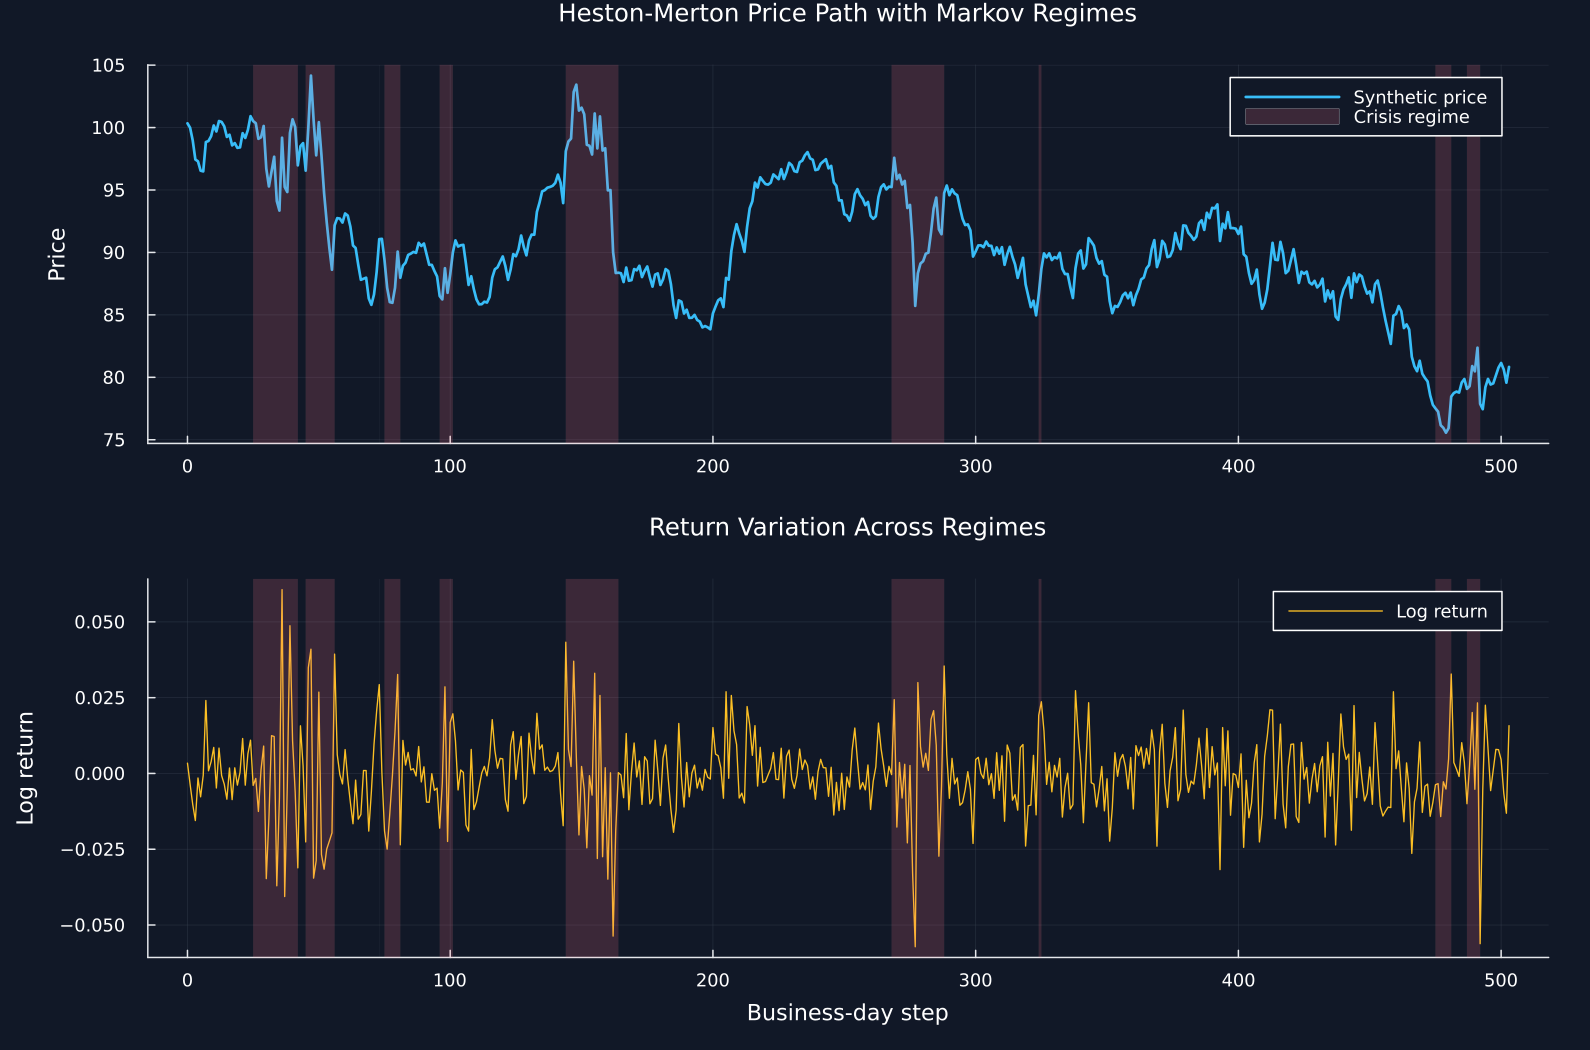

In [3]:
total_time, n_steps = 2., 504
regime_states = simulate_markov_path(transition_matrix, n_steps; seed=20260930)
regime_path = regime_names[regime_states]
parameter_vectors = Dict(key=>[regimes[name][key] for name in regime_path] for key in parameter_keys)
regime_change = vcat(false, diff(regime_states).!=0)
log_returns = RiskLabAI.Data.heston_merton_log_returns(total_time, n_steps, (parameter_vectors[key] for key in parameter_keys)..., regime_change; random_state=Xoshiro(20260931))
prices = 100 .* exp.(cumsum(log_returns))
step_index = collect(0:n_steps-1)
price_panel = plot(step_index, prices; color=palette.cyan, linewidth=1.8, label="Synthetic price", ylabel="Price", title="Heston-Merton Price Path with Markov Regimes")
shade_crisis!(price_panel, regime_states; label="Crisis regime")
return_panel = plot(step_index, log_returns; color=palette.amber, linewidth=0.9, label="Log return", xlabel="Business-day step", ylabel="Log return", title="Return Variation Across Regimes")
shade_crisis!(return_panel, regime_states)
figure = plot(price_panel, return_panel; layout=(2, 1), link=:x, size=(1060, 700))
save_data(DataFrame("Business-day step"=>step_index, "Regime"=>regime_path, "Price"=>prices, "Log return"=>log_returns), paths, "regime_price_path")
save_figure(figure, paths, "regime_price_path")


## Monte Carlo Uncertainty

The first expression is an approximate 95 percent interval, and the second gives its large-sample normal justification:

$$
\widehat\psi_M\pm z_{0.975}\frac{s_g}{\sqrt M},\qquad
\sqrt M\,(\widehat\psi_M-\psi)\Rightarrow\mathcal N(0,\sigma_g^2).
$$

Here, $\widehat\psi_M$ is the average from $M$ simulations; $\psi$ is the target mean; $s_g$ is the sample standard deviation. $z_{0.975}$ is the 97.5th percentile of a standard normal distribution; $\sigma_g^2$ is the variance of the measured quantity; $\Rightarrow$ denotes convergence in distribution.

In [4]:
path_count, monte_carlo_steps = 400, 252
master_generator = Xoshiro(20260932)
seed_pairs = permutedims(reshape(rand(master_generator, UInt32, 2*path_count), 2, :))
terminal_log_returns, terminal_prices, crisis_fractions = zeros(path_count), zeros(path_count), zeros(path_count)
for path_index in 1:path_count
    states = simulate_markov_path(transition_matrix, monte_carlo_steps; seed=seed_pairs[path_index, 1])
    names_for_path = regime_names[states]
    vectors = Dict(key=>[regimes[name][key] for name in names_for_path] for key in parameter_keys)
    changes = vcat(false, diff(states).!=0)
    path_returns = RiskLabAI.Data.heston_merton_log_returns(1., monte_carlo_steps, (vectors[key] for key in parameter_keys)..., changes; random_state=Xoshiro(seed_pairs[path_index, 2]))
    terminal_log_returns[path_index] = sum(path_returns)
    terminal_prices[path_index] = 100*exp(terminal_log_returns[path_index])
    crisis_fractions[path_index] = mean(states.==2)
end

function summary_row(name, values)
    estimate = mean(values)
    standard_error = std(values)/sqrt(length(values))
    return (; quantity=name, estimate, standard_error, lower=estimate-1.96*standard_error, upper=estimate+1.96*standard_error)
end

loss_indicators = terminal_prices.<100
monte_carlo_summary = DataFrame([summary_row("Terminal log return", terminal_log_returns), summary_row("Terminal price", terminal_prices), summary_row("Loss probability", Float64.(loss_indicators)), summary_row("Crisis time fraction", crisis_fractions)])
rename!(monte_carlo_summary, ["Quantity", "Estimate", "Monte Carlo standard error", "Lower 95 percent limit", "Upper 95 percent limit"])
save_table(monte_carlo_summary, paths, "monte_carlo_summary"; caption="Monte Carlo estimates, standard errors, and normal-approximation intervals from 400 paths.", label="tab:monte-carlo-summary")
save_data(DataFrame("State seed"=>seed_pairs[:, 1], "Return seed"=>seed_pairs[:, 2], "Terminal log return"=>terminal_log_returns, "Terminal price"=>terminal_prices, "Loss indicator"=>loss_indicators, "Crisis time fraction"=>crisis_fractions), paths, "monte_carlo_paths");


Row,Quantity,Estimate,Monte Carlo standard error,Lower 95 percent limit,Upper 95 percent limit
,String,Float64,Float64,Float64,Float64
1,Terminal log return,0.0181719,0.0107808,-0.00295836,0.0393022
2,Terminal price,104.2,1.125,101.995,106.405
3,Loss probability,0.46,0.0249511,0.411096,0.508904
4,Crisis time fraction,0.190794,0.00425816,0.182448,0.19914


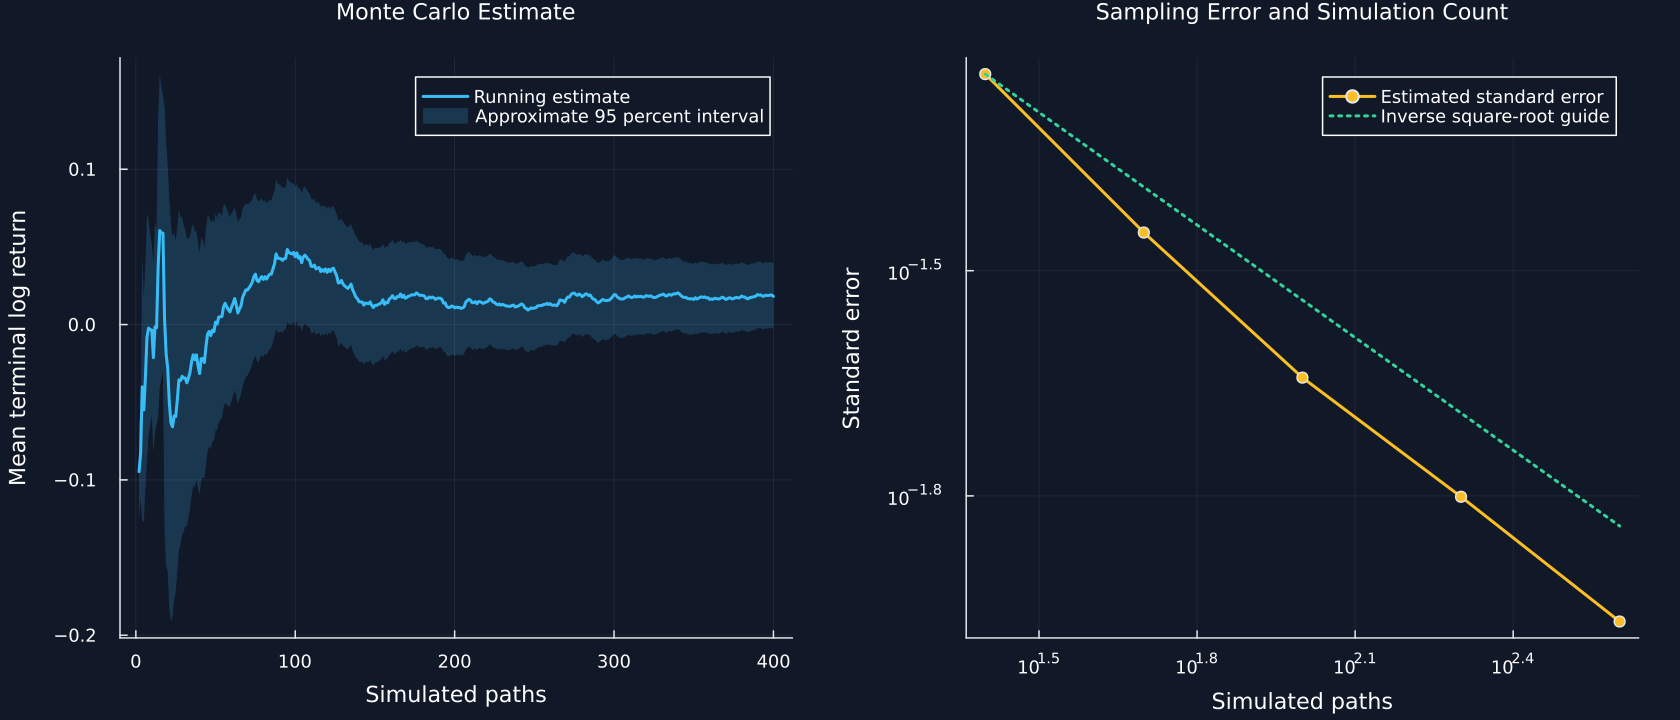

In [5]:
running_count = collect(2:path_count)
running_mean = [mean(terminal_log_returns[1:count]) for count in running_count]
running_standard_error = [std(terminal_log_returns[1:count])/sqrt(count) for count in running_count]
evaluation_counts = [25, 50, 100, 200, 400]
evaluated_standard_errors = [std(terminal_log_returns[1:count])/sqrt(count) for count in evaluation_counts]
inverse_square_root_guide = evaluated_standard_errors[1].*sqrt.(evaluation_counts[1]./evaluation_counts)
estimate_panel = plot(running_count, running_mean; color=palette.cyan, label="Running estimate", xlabel="Simulated paths", ylabel="Mean terminal log return", title="Monte Carlo Estimate")
plot!(estimate_panel, running_count, running_mean .- 1.96 .* running_standard_error; fillrange=running_mean .+ 1.96 .* running_standard_error, linealpha=0, fillalpha=0.20, color=palette.cyan, label="Approximate 95 percent interval")
error_panel = plot(evaluation_counts, evaluated_standard_errors; xscale=:log10, yscale=:log10, marker=:circle, color=palette.amber, label="Estimated standard error", xlabel="Simulated paths", ylabel="Standard error", title="Sampling Error and Simulation Count")
plot!(error_panel, evaluation_counts, inverse_square_root_guide; color=palette.green, linestyle=:dot, label="Inverse square-root guide")
figure = plot(estimate_panel, error_panel; layout=(1, 2), size=(1120, 480), titlefontsize=10)
save_data(DataFrame("Simulated paths"=>running_count, "Mean terminal log return"=>running_mean, "Standard error"=>running_standard_error), paths, "monte_carlo_running_estimates")
save_data(DataFrame("Simulated paths"=>evaluation_counts, "Standard error"=>evaluated_standard_errors, "Inverse square-root guide"=>inverse_square_root_guide), paths, "monte_carlo_standard_errors")
save_figure(figure, paths, "monte_carlo_uncertainty")


## Tests

In [6]:
repeated_states = simulate_markov_path(transition_matrix, n_steps; seed=20260930)
repeated_returns = RiskLabAI.Data.heston_merton_log_returns(total_time, n_steps, (parameter_vectors[key] for key in parameter_keys)..., regime_change; random_state=Xoshiro(20260931))
@assert calm_length == crisis_length == 1
@assert aligned_calm["mu"] == [regimes["Calm"]["mu"]]
@assert aligned_crisis["v"] == [regimes["Crisis"]["v"]]
@assert vec(sum(transition_matrix; dims=2)) ≈ ones(2)
@assert all(transition_matrix .>= 0)
@assert transition_matrix'*stationary_distribution ≈ stationary_distribution
@assert sum(stationary_distribution) ≈ 1
@assert regime_states == repeated_states
@assert log_returns == repeated_returns
@assert size(prices) == size(log_returns) == size(regime_states) == (n_steps,)
@assert all(isfinite, prices) && all(prices .> 0)
@assert length(unique(seed_pairs[:, 1])) == path_count
@assert length(unique(seed_pairs[:, 2])) == path_count
@assert all(isfinite, terminal_prices) && all(terminal_prices .> 0)
@assert all(monte_carlo_summary[!, "Monte Carlo standard error"] .> 0)
@assert all(monte_carlo_summary[!, "Lower 95 percent limit"] .< monte_carlo_summary.Estimate)
@assert all(monte_carlo_summary.Estimate .< monte_carlo_summary[!, "Upper 95 percent limit"])
@assert abs(mean(crisis_fractions)-stationary_distribution[2]) < 0.08
@assert evaluated_standard_errors[end] < evaluated_standard_errors[1]
